# Laboratorio 3B · Verificar una política de negocio con Z3

En **MantenIA**, la empresa ficticia de mantenimiento industrial del curso, cada compra de repuestos necesita una aprobación. Quién la da depende del monto y de si el proveedor está **homologado**, es decir, evaluado y aprobado por la empresa. La política tiene cinco reglas, y cada una, leída sola, es razonable. La gerente de compras pregunta algo que nadie ha revisado: *«¿funcionan juntas?»*. ¿Hay compras que nadie puede aprobar? ¿Hay compras que ninguna regla cubre?

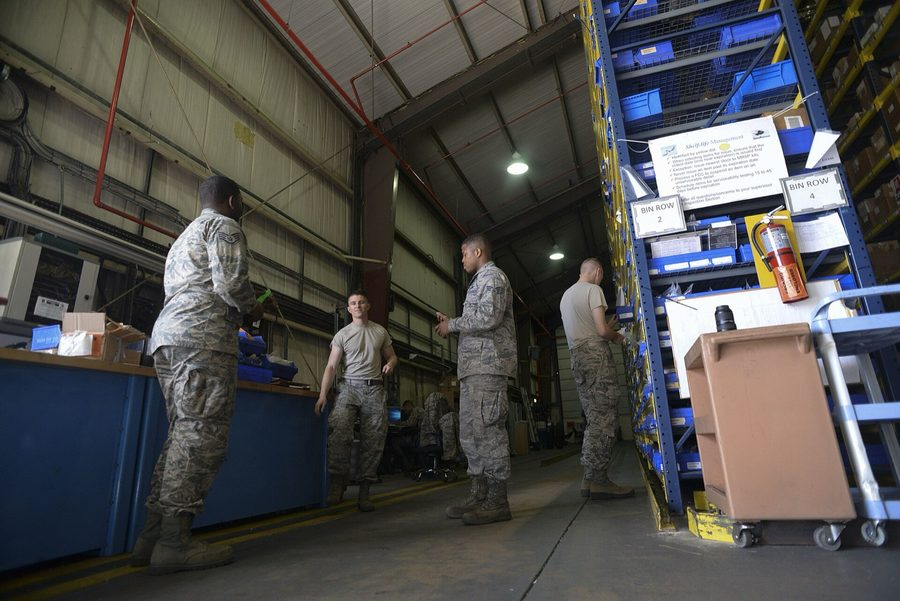

*Almacén de repuestos. Foto: Alexandria Lee, U.S. Air Force (2018), [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Aircraft_parts_store-_No_one_flies_without_supplies_%284654657%29.jpg), dominio público.*

Revisar cien casos a mano no responde la pregunta: solo dice que esos cien funcionan. Un **solver lógico** como **Z3** sí la responde: busca un caso que rompa la política entre todos los posibles. Si lo encuentra, lo muestra como **contraejemplo**; si no existe, lo **demuestra**.

En este laboratorio usted:
* Escribirá la política como una tabla de reglas, sin programar: el notebook la traduce a la lógica de Z3.
* Le hará a Z3 las tres preguntas de la verificación: ¿se contradice?, ¿tiene lagunas?, ¿qué pasa en los bordes?
* Corregirá la política hasta que Z3 demuestre que ya no tiene esos problemas.
* Ampliará la política con dos reglas nuevas y distinguirá los problemas del texto de los problemas de la lectura.
* Comparará dos usos de un LLM: como **traductor** de la política, revisado por Z3, y como **auditor** que razona solo.

| | |
| :--- | :--- |
| **Resultados de aprendizaje** | RA4 (modelar reglas en lógica y verificar formalmente su validez con un solver) y RA8 (evaluar sistemas híbridos LLM + técnicas clásicas según su validez, su costo y la fidelidad de sus explicaciones). |
| **Tiempo** | 60 minutos en clase (secciones 0 a 5) y unos 30 en casa: la sección 6.1 y, si no alcanzó en clase, el análisis de la 5.3. La sección 6.2 es el punto de partida del trabajo independiente TI-2. |
| **Modalidad** | En parejas. **No se escribe código:** se editan tablas. |
| **Entrega** | Este notebook ejecutado y el archivo `resultados_3B.csv`, al inicio de la semana 3 del curso (sección 7). |

## Contenido

* [Antes de empezar](#0) · *en clase, 5 min*
* [1 - La política como tabla](#1) · *en clase, 8 min*
* [2 - Las tres preguntas a Z3](#2) · *en clase, 12 min*
* [3 - Corregir la política](#3) · *en clase, 8 min*
* [4 - Ampliar la política](#4) · *en clase, 10 min*
* [5 - Contrapunto: el LLM traduce o razona solo](#5) · *en clase, 15 min; el análisis escrito se puede terminar en casa*
* [6 - Para casa: corregir la ampliada y su propia política](#6) · *para casa*
* [7 - Inténtelo usted mismo, entrega y criterios](#7)
* [Conclusión](#conclusion) · [Referencias](#referencias)

<details>
<summary><b>💡 Otra forma de navegar: el panel Esquema de VS Code</b> (clic para desplegar)</summary>

VS Code lista todos los títulos de este notebook en el panel **Esquema** (*Outline*), dentro del Explorador de la barra lateral izquierda. Al hacer clic en un título, el notebook salta a esa sección.

</details>

<a id='0'></a>
## Antes de empezar

Ejecute las celdas **en orden**. Solo se editan las celdas marcadas con ✏️: en ellas se cambian tablas, nombres o textos, nunca código.

<details>
<summary><b>Cómo usar este notebook en VS Code</b> (si lo necesita)</summary>

1. Con **Archivo › Abrir carpeta**, abra la carpeta del curso, la que contiene el entorno `.venv`.
2. Abra este notebook y, en **Seleccionar kernel** (arriba a la derecha), elija el entorno `.venv` del curso.
3. Ejecute cada celda con **Shift + Enter** o con el botón ▷ de su izquierda.
4. Para editar una celda de texto, como las de análisis, haga doble clic sobre ella; para verla de nuevo, **Shift + Enter**.
5. Si algo falla, lea el mensaje: los módulos de apoyo explican en español qué revisar. Un error de escritura en una tabla aparece en rojo al ejecutar la celda que usa esa tabla, y nombra la regla. Si el problema persiste, use **Reiniciar** y luego **Ejecutar todo**.

</details>

<details>
<summary><b>Las tres vías de acceso a un LLM</b> (para la sección 5)</summary>

1. **La API de un proveedor** (Anthropic, OpenAI o Google Gemini), con una clave en un archivo `.env` de esta carpeta o de una superior: una línea como `ANTHROPIC_API_KEY=su-clave`. **Nunca** escriba la clave en el notebook.
2. **Un modelo local** con Ollama, sin clave ni costo.
3. **Respuestas grabadas** de una corrida real anterior: el notebook corre completo, pero no puede probar instrucciones nuevas.

MantenIA y su política son ficticias. No envíe a un servicio externo datos reales de su organización sin autorización.

</details>

<details>
<summary><b>Respaldo: trabajar en Google Colab</b> (solo si no puede usar VS Code)</summary>

1. Pida al docente el archivo `lab_3B_politicas_z3.zip` y abra el notebook en [Colab](https://colab.research.google.com/) con **Archivo › Subir notebook**.
2. Suba el .zip a la carpeta `/content` en el panel **Archivos** de Colab.
3. Si tiene una clave de API, guárdela en los **Secrets** de Colab con el nombre `ANTHROPIC_API_KEY`. En Colab no funciona el modelo local.

</details>

* Ejecute la siguiente celda para preparar el entorno: comprueba Python e instala lo que falte, incluido Z3.

In [ ]:
# Preparar el entorno: comprobar Python e instalar lo que falte de requirements.txt (incluido z3-solver)
import os, pathlib, sys, zipfile
if "google.colab" in sys.modules and not pathlib.Path("entorno.py").exists():
    # Respaldo en Colab: descomprimir la carpeta del laboratorio que usted subió como .zip
    zipfile.ZipFile("/content/lab_3B_politicas_z3.zip").extractall("/content")
    os.chdir("/content/lab_3B_politicas_z3")
import entorno
entorno.preparar()

El laboratorio usa tres módulos de apoyo, en la misma carpeta del notebook.

<details>
<summary><b>Qué hace cada módulo</b> (clic para desplegar)</summary>

* `politicas` lee las tablas de la política, las traduce a fórmulas de Z3 y hace las verificaciones. También le pide al LLM que traduzca o que razone, y exporta los resultados.
* `cliente_llm` envía las instrucciones al LLM por cualquiera de las tres vías y registra los tokens, el tiempo y el costo de cada llamada.
* `presentacion` muestra tablas, recuadros y conversaciones.

</details>

* Ejecute la siguiente celda para importar los módulos.

In [ ]:
# Importar los módulos de apoyo del laboratorio
import politicas as pz
import presentacion as p
import cliente_llm

<a id='0-1'></a>
### 0.1 - Elegir el LLM

El LLM solo se usa en la sección 5. El de Anthropic por defecto es **Claude Haiku 5.5**, sin modo de razonamiento: todo el laboratorio cuesta menos de un centavo de dólar por pareja. Un LLM lee y escribe en **tokens**, fragmentos de palabra, y los proveedores cobran por millón de tokens de entrada y de salida. El notebook los cuenta en cada llamada.

* Ejecute la siguiente celda para ver las vías disponibles.

In [ ]:
# Ver qué vías de acceso a un LLM están disponibles (no muestra ninguna clave)
p.mostrar_tabla(cliente_llm.estado_proveedores(), titulo="Vías de acceso a un LLM en este computador")

Para forzar una vía, cámbiela en la celda siguiente; por ejemplo, `PROVEEDOR = "grabado"`. Con `None`, el notebook elige.

* Ejecute la siguiente celda para crear el cliente del LLM.

In [ ]:
# ✏️ Configuración del LLM: deje None para que el notebook elija la primera vía disponible
PROVEEDOR = None    # "anthropic", "openai", "gemini", "ollama" o "grabado"
MODELO_LLM = None   # None usa el LLM por defecto del proveedor
llm = cliente_llm.ClienteLLM(proveedor=PROVEEDOR, modelo=MODELO_LLM)

<a id='1'></a>
## 1 - La política como tabla

*En clase, 8 minutos.* Esta es la política de compras de repuestos de MantenIA, tal como está escrita:

> **R1.** Las compras a proveedores homologados de **menos de** \$2.000.000 las aprueba el supervisor.
> **R2.** Las compras a proveedores homologados de **más de** \$2.000.000 y **hasta** \$10.000.000 las aprueba el jefe de planta.
> **R3.** Las compras de más de \$10.000.000 las aprueba el gerente.
> **R4.** Las compras a proveedores no homologados las aprueba el gerente.
> **R5.** El gerente no aprueba compras de menos de \$1.000.000.

Para que un solver la revise, cada regla se vuelve una **regla si… entonces…** sin ambigüedades: *si* el proveedor está homologado *y* el monto es menor que 2.000.000, *entonces* el aprobador es el supervisor. George Boole propuso en 1854 tratar así el razonamiento, como un álgebra de afirmaciones verdaderas o falsas unidas con «y», «o» y «no». Sobre esa idea se construye la lógica que usan hoy los solvers.

Aquí la política se escribe en **dos tablas**:

* **Campos:** los datos de cada caso. Un **número** (el monto, con su mínimo y su máximo), una **categoría** (el proveedor) y la **decisión** (quién aprueba).
* **Reglas:** cada fila tiene un `id`, una condición `si` y un efecto `entonces`. La condición une comparaciones con «y»: `<`, `<=`, `>`, `>=`, `=` y `≠` (si no encuentra `≠` en el teclado, escriba `!=`). Los números son enteros y pueden llevar puntos de miles. El efecto dice quién decide (`aprobador = supervisor`) o prohíbe a alguien (`aprobador ≠ gerente`); la columna `tipo` de la tabla que verá lo indica: *decide* o *prohíbe*.

<details>
<summary><b>Para profundizar: SAT, SMT y Z3</b></summary>

Un solver **SAT** responde una sola pregunta: ¿existe una forma de dar valores verdadero o falso a las variables para que una fórmula sea verdadera? Si existe, responde `sat` y muestra un ejemplo; si no, responde `unsat`, y eso es una demostración de que no hay ninguno. Las reglas de negocio hablan de montos y categorías, no solo de verdadero y falso. Por eso se usa un solver **SMT** (satisfacibilidad módulo teorías), que agrega números y comparaciones. **Z3** es un solver SMT de Microsoft Research (de Moura y Bjørner, 2008), gratuito y de código abierto. Este notebook traduce sus tablas a fórmulas de Z3; usted no necesita escribirlas.

</details>

* Ejecute la siguiente celda para leer la política y mostrarla.

In [ ]:
# La política de compras de MantenIA, escrita como dos tablas de texto
CAMPOS = """
| campo     | tipo      | valores                             |
|-----------|-----------|-------------------------------------|
| monto     | número    | 1 a 100.000.000                     |
| proveedor | categoría | homologado, no homologado           |
| aprobador | decisión  | supervisor, jefe de planta, gerente |
"""
REGLAS = """
| id | si                                                               | entonces                   |
|----|------------------------------------------------------------------|----------------------------|
| R1 | proveedor = homologado y monto < 2.000.000                       | aprobador = supervisor     |
| R2 | proveedor = homologado y monto > 2.000.000 y monto <= 10.000.000 | aprobador = jefe de planta |
| R3 | monto > 10.000.000                                               | aprobador = gerente        |
| R4 | proveedor = no homologado                                        | aprobador = gerente        |
| R5 | monto < 1.000.000                                                | aprobador ≠ gerente        |
"""
politica = pz.Politica(CAMPOS, REGLAS, "Política de compras")
politica.mostrar()

El **mapa de casos** dibuja la política. Cada fila es un tipo de proveedor y el eje horizontal es el monto. Cada tramo tiene el color de quien aprueba. Las columnas angostas son los valores exactos de cada umbral, como \$2.000.000. Un tramo rayado en rojo es un **choque** (una contradicción) y uno blanco con borde rojo es una **laguna**.

* Ejecute la siguiente celda para dibujar el mapa. Pase el cursor sobre un tramo para ver el caso.

In [ ]:
# Dibujar la política como un mapa de casos
politica.mapa()

<a id='2'></a>
## 2 - Las tres preguntas a Z3

*En clase, 12 minutos.* Verificar una política es hacerle tres preguntas, y cada una se formula como la **búsqueda de un error**. Si el error existe, Z3 responde `sat` (*satisfacible*: hay al menos un caso) y lo muestra. Si no existe, responde `unsat` (*insatisfacible*), y eso es una **demostración**: ningún caso, entre todos los posibles, tiene ese error.

<a id='2-1'></a>
### 2.1 - ¿Se contradice?

Una **contradicción** es un caso en el que las reglas que aplican exigen cosas incompatibles: ningún aprobador las cumple todas a la vez.

**Desglose del experimento**

| Entrada | Lo que debería pasar | Por qué, o cómo puede fallar |
| :--- | :--- | :--- |
| La política de cinco reglas | Z3 busca una compra que nadie pueda aprobar sin romper una regla | Si la encuentra, responde `sat` y muestra el caso. El notebook pide el monto más alto con ese problema, para que el ejemplo sea realista |

* Ejecute la siguiente celda para buscar contradicciones.

In [ ]:
# Pregunta 1: ¿hay una compra que nadie puede aprobar sin romper una regla?
contradicciones, segundos = pz.medir(politica.contradicciones)
pz.mostrar_hallazgos(politica, contradicciones, "contradicción")
print(f"Z3 tardó {segundos} s.")

**Análisis.** Z3 encuentra una compra de \$999.999 a un proveedor no homologado. R4 dice que la aprueba el gerente; R5 dice que el gerente no aprueba compras de menos de un millón. Ningún aprobador cumple las dos. No es un caso aislado: todo el tramo por debajo del millón, con proveedores no homologados, tiene el mismo problema (es el tramo rayado del mapa).

Fíjese en la forma de la respuesta: **el contraejemplo es la explicación**. No es un razonamiento que haya que creer, sino un caso concreto que cualquier persona puede comprobar contra el texto de la política.

<a id='2-2'></a>
### 2.2 - ¿Tiene lagunas?

Una **laguna** es un caso que ninguna regla decide: no hay ninguna regla que diga quién aprueba. Las prohibiciones, como R5, no cuentan: dicen quién no, pero no quién sí.

* Ejecute la siguiente celda para buscar lagunas.

In [ ]:
# Pregunta 2: ¿hay una compra para la que ninguna regla dice quién aprueba?
lagunas, segundos = pz.medir(politica.lagunas)
pz.mostrar_hallazgos(politica, lagunas, "laguna")
print(f"Z3 tardó {segundos} s.")

**Análisis.** La laguna es una sola compra: exactamente \$2.000.000 a un proveedor homologado. R1 dice «menos de», R2 dice «más de», y el borde quedó sin dueño. Es el tipo de error que una revisión humana casi nunca ve, porque está en un solo valor. Z3 lo encuentra porque no revisa ejemplos: razona sobre todos los casos a la vez.

<a id='2-3'></a>
### 2.3 - ¿Qué pasa en los bordes?

Los problemas suelen esconderse en los **umbrales** de las reglas: \$1.000.000, \$2.000.000 y \$10.000.000. La tabla siguiente evalúa, para cada tipo de proveedor, cada umbral y los montos de un peso menos y un peso más.

* Ejecute la siguiente celda para revisar los bordes.

In [ ]:
# Pregunta 3: los casos justo antes, en y justo después de cada umbral
p.mostrar_tabla(politica.bordes(), titulo="Casos límite de la política")

**Análisis.** La tabla confirma los dos problemas en su lugar exacto: la contradicción aparece en \$999.999 con proveedores no homologados, y la laguna en \$2.000.000 con homologados. En \$10.000.000 no hay problema: R2 dice «hasta» y R3 dice «más de», y los dos bordes encajan. Las palabras «menos de», «más de» y «hasta» deciden si un borde queda cubierto dos veces, una vez o ninguna.

<a id='3'></a>
## 3 - Corregir la política

*En clase, 8 minutos.* Ahora corrija la política **cambiando dos reglas** en la tabla de la celda siguiente. No hace falta agregar reglas.

<details>
<summary><b>Pista</b></summary>

* La laguna está en \$2.000.000: una de las dos reglas que tocan ese borde debe incluirlo. «Hasta» se escribe `<=`.
* La contradicción es entre R4 y R5: decida a qué compras debería aplicar R5. Se puede agregar una condición con `y`.

</details>

* Edite la tabla de la celda siguiente y ejecútela.

In [ ]:
# ✏️ Corrija dos reglas de la política para que Z3 no encuentre ni contradicciones ni lagunas
REGLAS_CORREGIDAS = """
| id | si                                                               | entonces                   |
|----|------------------------------------------------------------------|----------------------------|
| R1 | proveedor = homologado y monto < 2.000.000                       | aprobador = supervisor     |
| R2 | proveedor = homologado y monto > 2.000.000 y monto <= 10.000.000 | aprobador = jefe de planta |
| R3 | monto > 10.000.000                                               | aprobador = gerente        |
| R4 | proveedor = no homologado                                        | aprobador = gerente        |
| R5 | monto < 1.000.000                                                | aprobador ≠ gerente        |
"""

* Ejecute la siguiente celda para que Z3 revise su política corregida y la compare con la original.

In [ ]:
# Comprobar la política corregida: ¿Z3 responde unsat a las dos preguntas?
corregida = pz.Politica(CAMPOS, REGLAS_CORREGIDAS, "Política corregida")
c_corr, l_corr = corregida.contradicciones(), corregida.lagunas()
pz.mostrar_hallazgos(corregida, c_corr, "contradicción")
pz.mostrar_hallazgos(corregida, l_corr, "laguna")
if not c_corr and not l_corr:
    p.nota("Z3 demostró que la política corregida no tiene ni contradicciones ni lagunas.", "exito", "¡Bien hecho!")
else:
    p.nota("Todavía hay problemas: lea el contraejemplo y ajuste la regla que lo causa.", "aviso", "Siga intentando")
p.mostrar_tabla(politica.comparar(corregida), titulo="Qué cambió frente a la política original")

**Análisis.** Cuando Z3 responde `unsat` a las dos preguntas, **está demostrado** que ninguna compra, entre todas las posibles, queda sin aprobador ni con dos órdenes incompatibles. La tabla de comparación muestra, para cada regla que cambió, un caso en el que las dos versiones deciden distinto. Así se documenta una corrección: con el caso que la justifica.

> **Nota:** si limitó R5 a los proveedores homologados, su corrección es válida y basta. Fíjese, eso sí, en que R5 ya no cambia ninguna decisión, porque R1 ya pone al supervisor: Z3 también sirve para descubrir reglas que sobran.

<a id='4'></a>
## 4 - Ampliar la política

*En clase, 10 minutos.* La gerencia agrega dos reglas a la política original:

> **R6.** Si el equipo está detenido, el jefe de planta **puede** aprobar compras de hasta \$15.000.000.
> **R7.** Las compras de más de \$50.000.000 las aprueba el gerente general.

Eso exige un campo nuevo (`equipo_detenido`) y un aprobador nuevo (gerente general). La celda siguiente trae la tabla tal como la escribió alguien que leyó «**puede** aprobar» como «**aprueba**».

**Desglose del experimento**

| Entrada | Lo que debería pasar | Por qué, o cómo puede fallar |
| :--- | :--- | :--- |
| La política original más R6 y R7, leídas al pie de la letra | Z3 encuentra varias contradicciones; cada una dice qué par de reglas choca | Algunas vienen del texto de la política y otras de cómo se leyó «puede aprobar». Z3 no distingue unas de otras: esa es tarea de usted |

* Ejecute la siguiente celda para leer la política ampliada y verificarla.

In [ ]:
# La política ampliada, tal como la leyó alguien que entendió «puede aprobar» como «aprueba»
CAMPOS_AMPLIADA = """
| campo           | tipo      | valores                                              |
|-----------------|-----------|------------------------------------------------------|
| monto           | número    | 1 a 100.000.000                                      |
| proveedor       | categoría | homologado, no homologado                            |
| equipo_detenido | categoría | sí, no                                               |
| aprobador       | decisión  | supervisor, jefe de planta, gerente, gerente general |
"""
REGLAS_AMPLIADA = """
| id | si                                                               | entonces                    |
|----|------------------------------------------------------------------|-----------------------------|
| R1 | proveedor = homologado y monto < 2.000.000                       | aprobador = supervisor      |
| R2 | proveedor = homologado y monto > 2.000.000 y monto <= 10.000.000 | aprobador = jefe de planta  |
| R3 | monto > 10.000.000                                               | aprobador = gerente         |
| R4 | proveedor = no homologado                                        | aprobador = gerente         |
| R5 | monto < 1.000.000                                                | aprobador ≠ gerente         |
| R6 | equipo_detenido = sí y monto <= 15.000.000                       | aprobador = jefe de planta  |
| R7 | monto > 50.000.000                                               | aprobador = gerente general |
"""
ampliada = pz.Politica(CAMPOS_AMPLIADA, REGLAS_AMPLIADA, "Política ampliada")
ampliada.mostrar()
c_amp, l_amp = ampliada.contradicciones(), ampliada.lagunas()
pz.mostrar_hallazgos(ampliada, c_amp, "contradicción")
pz.mostrar_hallazgos(ampliada, l_amp, "laguna")

Z3 encuentra **seis contradicciones**, cada una con su par de reglas, y la laguna de siempre. Ahora la pregunta es suya: **¿de dónde viene cada contradicción?**

* **Del texto de la política:** las reglas, tal como están escritas, piden cosas incompatibles. Hay que cambiar el texto.
* **De la lectura:** el texto admite otra lectura que no produce el choque. Aquí la sospechosa es R6: «puede aprobar» es un **permiso** (el jefe de planta *también* puede aprobar), no una **obligación**.

<details>
<summary><b>Pista</b></summary>

Para cada contradicción, pregúntese si existe una lectura razonable del texto que evite el choque sin cambiar ninguna palabra. Empiece por las que involucran a R6: ¿siguen chocando si «puede» se lee como permiso? Una lectura debe salir de las palabras de la política. Un criterio externo, como «la regla más específica gana», no está escrito en ella: si lo usa para clasificar, dígalo en su frase.

</details>

* Complete la tabla de la celda siguiente con su clasificación y una frase de por qué.

**✏️ Clasificación de las contradicciones de la política ampliada**

| Reglas que chocan | ¿Del texto o de la lectura? | Por qué, en una frase |
| :--- | :--- | :--- |
| R3 y R7 | | |
| R4 y R7 | | |
| R3 y R6 | | |
| R4 y R6 | | |
| R1 y R6 | | |
| R4 y R5 | | |

<a id='5'></a>
## 5 - Contrapunto: el LLM traduce o razona solo

*En clase, 15 minutos.* Escribir la tabla de reglas a mano es la parte más lenta. ¿Puede hacerlo un LLM? Y si un LLM puede leer la política, ¿hace falta Z3? Esta sección compara dos formas de usar un LLM sobre la política ampliada.

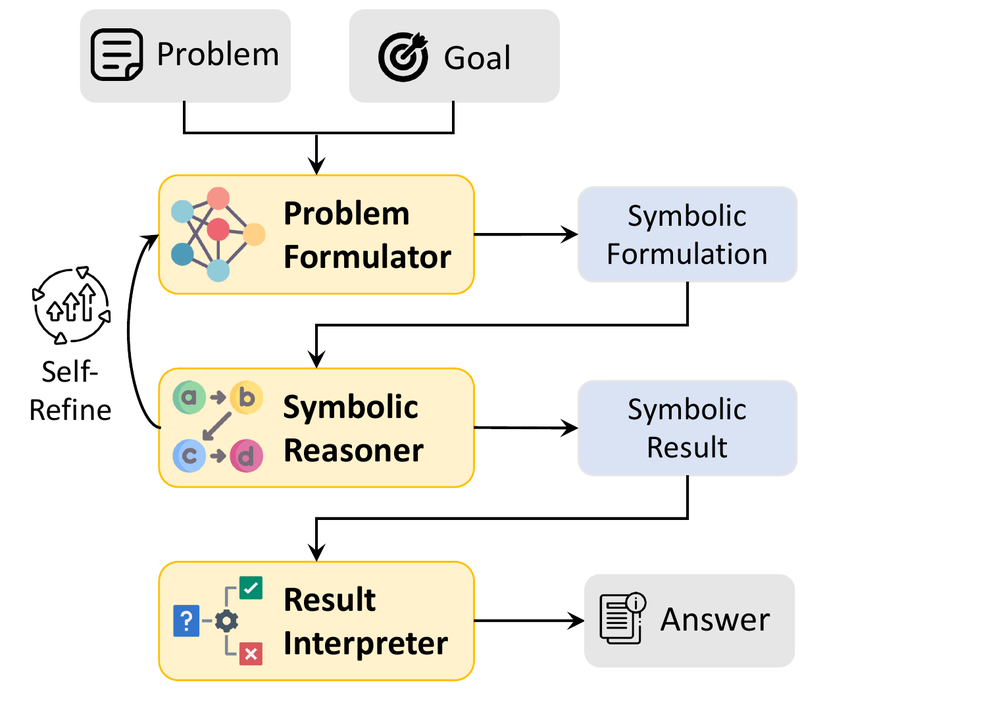

*El LLM formula el problema en lógica y un razonador simbólico lo resuelve; si el razonador rechaza la formulación, el error vuelve al LLM. Pan et al. (2023), Findings of EMNLP, Fig. 1, [ACL Anthology](https://aclanthology.org/2023.findings-emnlp.248/), CC BY 4.0.*

<a id='5-1'></a>
### 5.1 - El LLM como traductor, Z3 como verificador

El LLM recibe el texto de la política ampliada, los campos y la notación de la tabla, y devuelve las reglas. Si la tabla no se puede leer, el mensaje de error vuelve al LLM para que la corrija, como en el ciclo de la figura.

**Desglose del experimento**

| Entrada | Lo que debería pasar | Por qué, o cómo puede fallar |
| :--- | :--- | :--- |
| El texto de las siete reglas | El LLM devuelve una tabla que el notebook puede leer; luego se compara, regla por regla, con la tabla de la sección 4 y Z3 la verifica | El LLM puede cambiar un borde («menos de» por «hasta»), inventar un valor o elegir una lectura de «puede aprobar». Z3 verifica la tabla del LLM, no el texto |

> **Nota:** con la vía de respuestas grabadas, el LLM no se consulta: el notebook reproduce las respuestas de una corrida real anterior, con su proveedor, su modelo y su fecha.

* Ejecute la siguiente celda para pedirle la traducción al LLM.

In [ ]:
# El LLM traduce el texto de la política ampliada a la tabla de reglas; Z3 compara y verifica
texto_ampliada = pathlib.Path("politicas/compras_ampliada.md").read_text(encoding="utf-8")
traduccion = pz.traducir(llm, texto_ampliada, CAMPOS_AMPLIADA, etiqueta="3b/traduccion")
p.mostrar_conversacion(traduccion.conversacion, titulo="Conversación con el LLM (traducción)")
if traduccion.politica:
    p.mostrar_tabla(ampliada.comparar(traduccion.politica), titulo="La tabla de la sección 4 frente a la del LLM")
    c_llm, l_llm = traduccion.politica.contradicciones(), traduccion.politica.lagunas()
    p.mostrar_tabla(pz.tabla_hallazgos(traduccion.politica, c_llm + l_llm), titulo="Lo que encuentra Z3 en la tabla del LLM")
else:
    p.nota(f"No hubo una tabla legible: {traduccion.error}", "aviso")
p.mostrar_tabla([traduccion.metricas()], titulo="Llamadas, tokens, costo y tiempo de la traducción")

**Análisis.** Lea el resultado con estas preguntas, sea cual sea:
* **Si la tabla del LLM es igual a la de la sección 4**, el LLM hizo la misma lectura literal de «puede aprobar» y Z3 encuentra los mismos choques: la ambigüedad del texto no la resuelve el traductor.
* **Si alguna regla difiere,** ¿es un error del LLM (un borde cambiado, una condición omitida, un aprobador que el texto no menciona), una lectura más fiel de «puede», o las dos cosas?
* **En los dos casos, la garantía de Z3 vale para la traducción, no para el texto.** Si el LLM cambió un «menos de» por un «hasta», Z3 verificó otra política. Alguien debe revisar la traducción.

<a id='5-2'></a>
### 5.2 - El LLM como auditor que razona solo

Ahora el LLM no traduce: lee la política y responde directamente si hay contradicciones o lagunas, **pensando paso a paso** (cadena de pensamiento) y dando un caso concreto por cada problema. El notebook comprueba con Z3 cada caso que propone.

**Desglose del experimento**

| Entrada | Lo que debería pasar | Por qué, o cómo puede fallar |
| :--- | :--- | :--- |
| El texto de las siete reglas | El LLM razona y propone casos; Z3 comprueba si cada uno es un problema real | El LLM puede encontrar algunos problemas y no otros, proponer casos que no son problemas o no terminar su respuesta. Su razonamiento puede sonar convincente aunque esté incompleto |

* Ejecute la siguiente celda para pedirle la auditoría al LLM.

In [ ]:
# El LLM razona solo sobre la política ampliada; Z3 comprueba cada caso que propone
auditoria = pz.razonar(llm, texto_ampliada, CAMPOS_AMPLIADA, etiqueta="3b/razonar")
p.mostrar_conversacion(auditoria.conversacion, titulo="Conversación con el LLM (auditoría)")
if auditoria.error:
    p.nota(auditoria.error, "aviso")
p.mostrar_tabla(pz.revisar_casos_del_llm(ampliada, auditoria), titulo="¿Son reales los casos que propuso el LLM?")
p.mostrar_tabla(pz.cobertura(ampliada, auditoria, c_amp, l_amp), titulo="¿Encontró el LLM los problemas que encontró Z3?")
p.mostrar_tabla([auditoria.metricas()], titulo="Llamadas, tokens, costo y tiempo de la auditoría")

**Análisis.** Compare las dos tablas:
* **Casos falsos y problemas omitidos.** Un caso falso es una explicación convincente de algo que no pasa. Un problema omitido no se anuncia: una auditoría incompleta se lee igual que una completa.
* **¿Omisión u otra lectura?** Use su clasificación de la sección 4. Si el LLM descartó un choque con R6 por leer «puede» como permiso, hizo otra lectura. Si descartó un choque que viene del texto, es una omisión, y su argumento tiene un error que usted puede señalar.
* **Fidelidad.** Z3 solo comprueba los casos del bloque final; lo que el LLM afirma en su razonamiento hay que revisarlo a mano. Turpin et al. (2023) mostraron que una cadena de pensamiento puede ser plausible sin ser fiel. El contraejemplo de Z3 no depende de creerle a nadie.

<a id='5-3'></a>
### 5.3 - Registro y su análisis

El archivo `resultados_3B.csv` usa las mismas columnas que los demás laboratorios de **contrapunto** del curso, los que comparan un LLM con una técnica clásica: en la sesión 8 se analizan juntos. La columna `tokens_razonamiento` queda en cero, porque el modo de razonamiento del LLM está desactivado. En el CSV, `correcto` vale 1 para la traducción si la tabla del LLM es igual a la de la sección 4, y para la auditoría si encontró todos los problemas de Z3 sin casos falsos; es una medida de coincidencia, no de quién tiene la razón. Si el tiempo de clase no alcanza, escriba el análisis en casa.

* Escriba los nombres de la pareja en la celda siguiente y ejecútela.

In [ ]:
# ✏️ Nombres de la pareja, para el CSV
PAREJA = "Nombre 1 y Nombre 2"

* Ejecute la siguiente celda para registrar los tres métodos en `resultados_3B.csv`.

In [ ]:
# Registrar los tres métodos sobre la política ampliada y exportar el CSV común
problemas_z3 = len(c_amp) + len(l_amp)
_, t_z3 = pz.medir(lambda: (ampliada.contradicciones(), ampliada.lagunas()))
filas = [pz.fila_csv("compras_ampliada", "clasico", "Z3 sobre la tabla", True,
                     f"contradicciones: {len(c_amp)}; lagunas: {len(l_amp)}", {"tiempo_s": t_z3})]
if traduccion.politica:
    distintas = [f["regla"] for f in ampliada.comparar(traduccion.politica) if f["resultado"] != "igual"]
    filas.append(pz.fila_csv("compras_ampliada", "hibrido", "LLM traduce y Z3 verifica", not distintas,
                             f"tabla con diferencias en {', '.join(distintas)}" if distintas else "tabla igual a la de la sección 4",
                             traduccion.metricas(), iteraciones=len(traduccion.respuestas)))
else:
    filas.append(pz.fila_csv("compras_ampliada", "hibrido", "LLM traduce y Z3 verifica", False, "sin tabla legible",
                             traduccion.metricas(), iteraciones=len(traduccion.respuestas)))
revision = pz.revisar_casos_del_llm(ampliada, auditoria)
cob = pz.cobertura(ampliada, auditoria, c_amp, l_amp)
encontrados = sum(f["¿lo encontró el LLM?"] == "sí" for f in cob)
falsos = sum(f["¿es real?"] == "no" for f in revision)
filas.append(pz.fila_csv("compras_ampliada", "llm", "LLM razona solo (cadena de pensamiento)",
                         encontrados == problemas_z3 and falsos == 0,
                         f"encontró {encontrados} de {problemas_z3} problemas; {falsos} casos falsos", auditoria.metricas()))
ruta = pz.exportar_csv(filas, PAREJA)
p.mostrar_tabla(filas, columnas=["metodo", "estrategia", "correcto", "resultado", "llamadas", "costo_usd", "tiempo_s"],
                titulo=f"Resultados guardados en {ruta}")

* Escriba su análisis en la celda siguiente, con base en **sus** salidas.

**✏️ Su análisis** (5 a 8 líneas)

1. ¿El LLM tradujo la política igual que la tabla de la sección 4? Si hubo diferencias, ¿eran errores o lecturas defendibles?
2. Como auditor que razona solo, ¿cuántos de los problemas de Z3 encontró, cuántos omitió (y cuáles de esos dependen de la lectura de R6) y propuso casos falsos?
3. Si tuviera que presentar el resultado a la gerencia de MantenIA, ¿qué usaría: la tabla del LLM verificada por Z3, la auditoría del LLM o los contraejemplos de Z3? ¿Por qué?

*Escriba aquí.*

<a id='6'></a>
## 6 - Para casa: corregir la ampliada y su propia política

*Para casa: la sección 6.1, unos 25 minutos. La sección 6.2 es el punto de partida del trabajo independiente TI-2 y cuenta en su tiempo.*

<a id='6-1'></a>
### 6.1 - Corregir la política ampliada

Corrija la tabla de la política ampliada hasta que Z3 responda `unsat` a las dos preguntas. Antes, decida cómo leer R6, escríbalo en la primera línea de la celda y anote quién debería poder aprobar, según su lectura, en cada uno de estos **casos de control**. La celda de comprobación los evalúa con su política: compare.

| Caso | Monto | Proveedor | Equipo detenido |
| :--- | ---: | :--- | :--- |
| 1 | \$1.500.000 | homologado | sí |
| 2 | \$5.000.000 | no homologado | sí |
| 3 | \$12.000.000 | homologado | sí |
| 4 | \$12.000.000 | homologado | no |
| 5 | \$20.000.000 | no homologado | sí |
| 6 | \$500.000 | no homologado | no |
| 7 | \$60.000.000 | no homologado | no | `unsat` no basta, porque una política sin contradicciones puede decir otra cosa que la que usted quería.

<details>
<summary><b>Pista</b></summary>

* El efecto puede admitir dos o más aprobadores: `aprobador = supervisor o jefe de planta`, o `aprobador = supervisor o jefe de planta o gerente`. Con la lectura de permiso, la fila de R6 dice quiénes pueden aprobar en su tramo, y las reglas que se cruzan con ella deben admitir lo mismo.
* Cuidado con los permisos: todas las reglas que aplican a un caso deben cumplirse a la vez. Si otra regla del mismo caso admite un solo aprobador, el permiso desaparece. Para que el jefe de planta de verdad pueda aprobar con el equipo detenido, las demás reglas que aplican en esos casos también deben admitirlo.
* Una regla se puede partir en dos con condiciones distintas, por ejemplo según `equipo_detenido`.
* Revise qué reglas deben terminar donde empieza R7.

</details>

* Edite la tabla de la celda siguiente y ejecútela.

In [ ]:
# ✏️ Para casa: corrija la política ampliada hasta que Z3 responda unsat a las dos preguntas
# Nuestra lectura de R6, en una línea: ...
REGLAS_AMPLIADA_CORREGIDA = """
| id | si                                                               | entonces                    |
|----|------------------------------------------------------------------|-----------------------------|
| R1 | proveedor = homologado y monto < 2.000.000                       | aprobador = supervisor      |
| R2 | proveedor = homologado y monto > 2.000.000 y monto <= 10.000.000 | aprobador = jefe de planta  |
| R3 | monto > 10.000.000                                               | aprobador = gerente         |
| R4 | proveedor = no homologado                                        | aprobador = gerente         |
| R5 | monto < 1.000.000                                                | aprobador ≠ gerente         |
| R6 | equipo_detenido = sí y monto <= 15.000.000                       | aprobador = jefe de planta  |
| R7 | monto > 50.000.000                                               | aprobador = gerente general |
"""

* Ejecute la siguiente celda para que Z3 revise su versión de la política ampliada y la dibuje.

In [ ]:
# Comprobar la política ampliada corregida
ampliada_corregida = pz.Politica(CAMPOS_AMPLIADA, REGLAS_AMPLIADA_CORREGIDA, "Política ampliada corregida")
c_ac, l_ac = ampliada_corregida.contradicciones(), ampliada_corregida.lagunas()
pz.mostrar_hallazgos(ampliada_corregida, c_ac, "contradicción")
pz.mostrar_hallazgos(ampliada_corregida, l_ac, "laguna")
if not c_ac and not l_ac:
    p.nota("Z3 demostró que su versión de la política ampliada no tiene ni contradicciones ni lagunas.", "exito", "¡Bien hecho!")
else:
    p.nota("Todavía hay problemas: lea qué reglas chocan en cada contradicción y ajuste esas reglas.", "aviso", "Siga intentando")
control = [{"monto": m, "proveedor": pr, "equipo_detenido": e} for m, pr, e in
           [(1_500_000, "homologado", "sí"), (5_000_000, "no homologado", "sí"), (12_000_000, "homologado", "sí"),
            (12_000_000, "homologado", "no"), (20_000_000, "no homologado", "sí"), (500_000, "no homologado", "no"),
            (60_000_000, "no homologado", "no")]]
p.mostrar_tabla([{"caso": ev["caso"], "quién puede aprobar": pz._decide(ev)} for ev in map(ampliada_corregida.evaluar, control)],
                titulo="Casos de control: ¿coincide con su lectura de R6?")
ampliada_corregida.mapa()

<a id='6-2'></a>
### 6.2 - Su propia política (trabajo independiente TI-2)

El trabajo independiente TI-2 pide verificar una política real de su organización. Escríbala aquí con sus propios campos y reglas, en el mismo formato. La celda trae como ejemplo una política de vacaciones; reemplácela por la suya. Los nombres de los campos van sin espacios (`equipo_detenido`, no `equipo detenido`) y los números son enteros: si necesita decimales, cambie de unidad, por ejemplo de horas a minutos. **Anonimice los datos**: no use nombres ni cifras confidenciales.

* Edite las tablas de la celda siguiente y ejecútela.

In [ ]:
# ✏️ Para casa (TI-2): su propia política. Reemplace el ejemplo de vacaciones por la de su organización
# Nombres de campo sin espacios (use _), números enteros y una sola decisión
CAMPOS_PROPIOS = """
| campo      | tipo      | valores                                |
|------------|-----------|----------------------------------------|
| dias       | número    | 1 a 30                                 |
| antiguedad | número    | 0 a 480                                |
| temporada  | categoría | alta, baja                             |
| aprueba    | decisión  | jefe directo, talento humano, gerencia |
"""
REGLAS_PROPIAS = """
| id | si                       | entonces                 |
|----|--------------------------|--------------------------|
| V1 | dias <= 5                | aprueba = jefe directo   |
| V2 | dias > 5 y dias <= 15    | aprueba = talento humano |
| V3 | dias > 15                | aprueba = gerencia       |
| V4 | temporada = alta y dias > 3 | aprueba = gerencia    |
| V5 | antiguedad < 12          | aprueba ≠ gerencia       |
"""

* Ejecute la siguiente celda para que Z3 verifique su política: contradicciones, lagunas y casos límite.

In [ ]:
# Verificar su propia política: campos, reglas, contradicciones, lagunas y bordes
propia = pz.Politica(CAMPOS_PROPIOS, REGLAS_PROPIAS, "Mi política")
propia.mostrar()
pz.mostrar_hallazgos(propia, propia.contradicciones(), "contradicción")
pz.mostrar_hallazgos(propia, propia.lagunas(), "laguna")
p.mostrar_tabla(propia.bordes(), titulo="Casos límite de mi política")

<a id='7'></a>
## 7 - Inténtelo usted mismo, entrega y criterios

<a id='7-1'></a>
### 7.1 - Inténtelo usted mismo

Esta sección es **opcional**. Algunas ideas:
* **Otro LLM.** Repita la auditoría de la sección 5.2 con otro LLM (por ejemplo, el modelo local con `OTRO_PROVEEDOR = "ollama"`, o `claude-sonnet-5-5`, más capaz y más costoso) y compare cuántos problemas encuentra.
* **Su política.** Pídale al LLM que traduzca el texto de su política del TI-2 y compare su tabla con la suya.
* **El sistema experto de la sesión 1.** Escriba como tabla, en la sección 6.2, la base de reglas del sistema experto de su trabajo independiente 1 y verifique con Z3 que sea consistente.
* **La variabilidad.** Con la API, repita la sección 5 dos o tres veces: ¿el LLM traduce y audita siempre igual?

* Complete la celda siguiente y ejecútela.

In [ ]:
# ✏️ Opcional: la auditoría de la sección 5.2 con otro LLM
OTRO_PROVEEDOR = None   # por ejemplo "ollama" para el modelo local; None: el mismo de la sección 0.1
OTRO_LLM = None         # por ejemplo "claude-sonnet-5-5"; None: el LLM por defecto
if OTRO_PROVEEDOR or OTRO_LLM:
    otro = cliente_llm.ClienteLLM(proveedor=OTRO_PROVEEDOR or llm.proveedor, modelo=OTRO_LLM, grabar=False)
    otra = pz.razonar(otro, texto_ampliada, CAMPOS_AMPLIADA, etiqueta="3b/razonar_otro")
    p.mostrar_tabla(pz.cobertura(ampliada, otra, c_amp, l_amp), titulo=f"Cobertura de {otro.modelo}")

<a id='7-2'></a>
### 7.2 - Entrega y criterios de evaluación

**Qué se entrega.** Este notebook ejecutado, con sus salidas visibles y las celdas ✏️ completas, y el archivo `resultados_3B.csv`. Uno por pareja, por el canal del curso, al inicio de la semana 3. No entregue su archivo `.env`.

**Resultados reproducibles.** Con la API, cada corrida del LLM puede dar resultados distintos. Ejecute el notebook completo (**Reiniciar** y **Ejecutar todo**) **antes** de escribir el análisis, y escríbalo sobre esas salidas.

| Criterio | Peso |
| :--- | :--- |
| Política corregida (sección 3) y política ampliada corregida (sección 6.1) con `unsat` en las dos preguntas; en la 6.1, fiel a la lectura de R6 que declararon | 30 % |
| Clasificación argumentada de las contradicciones de la política ampliada (sección 4) | 25 % |
| Análisis del contrapunto, coherente con las salidas y el CSV (sección 5) | 35 % |
| `resultados_3B.csv` completo, con el esquema común | 10 % |

La política propia de la sección 6.2 se evalúa con el trabajo independiente TI-2.

### ✏️ Declaración de uso de asistentes de IA

En este laboratorio el LLM es parte del ejercicio. Declare aquí solo el uso **adicional**: por ejemplo, si consultaron a un asistente para entender un resultado o redactar el análisis.

* Escriba su declaración en la celda siguiente.

**✏️ Declaración de uso de IA.** *Escriba aquí su declaración.*

<a id='conclusion'></a>
## Conclusión

Usted verificó una política de negocio como lo hacen los equipos que revisan reglas a gran escala. La escribió como reglas precisas, le hizo a Z3 las tres preguntas de la verificación y obtuvo, para cada problema, un **contraejemplo** que cualquier persona puede comprobar. Al corregirla, Z3 respondió `unsat`: no es que no encontrara errores, es que **demostró que no los hay**.

Con la política ampliada vio el límite de esa garantía: Z3 verifica las reglas que se le dan. Si el texto es ambiguo, como «puede aprobar», la lectura es una decisión humana, y un LLM que traduce puede tomar la misma decisión literal sin advertirlo. Y como auditor que razona solo, un LLM puede sonar convincente sin cubrir todos los casos.

La idea que une la sesión: **la IA propone y algo externo verifica**. En el Laboratorio 3A fue un programa escrito por la IA y revisado por ustedes; aquí, una tabla traducida por la IA y revisada por Z3. En el **trabajo independiente TI-2** aplicará lo mismo a una política de su organización, y en la **sesión 8** sus resultados se juntarán con los de los demás laboratorios de contrapunto.

<a id='referencias'></a>
## Referencias

* de Moura, L. y Bjørner, N. (2008). Z3: An efficient SMT solver. *TACAS 2008*, LNCS 4963, 337–340. [DOI](https://doi.org/10.1007/978-3-540-78800-3_24)
* Biere, A., Heule, M., van Maaren, H. y Walsh, T. (eds.) (2021). *Handbook of Satisfiability*, 2.ª ed. IOS Press. [Editorial](https://www.iospress.com/catalog/books/handbook-of-satisfiability-2)
* Pan, L., Albalak, A., Wang, X. y Wang, W. Y. (2023). Logic-LM: Empowering large language models with symbolic solvers for faithful logical reasoning. *Findings of EMNLP 2023*, 3806–3824. [ACL Anthology](https://aclanthology.org/2023.findings-emnlp.248/)
* Turpin, M., Michael, J., Perez, E. y Bowman, S. R. (2023). Language models don't always say what they think: Unfaithful explanations in chain-of-thought prompting. *NeurIPS 2023*, 74952–74965. [arXiv](https://arxiv.org/abs/2305.04388)
* Boole, G. (1854). *An Investigation of the Laws of Thought*. Walton and Maberly. [Internet Archive](https://archive.org/details/investigationofl00boolrich)
* Backes, J. et al. (2018). Semantic-based automated reasoning for AWS access policies using SMT. *FMCAD 2018*, 206–214. [PDF](https://cs.utexas.edu/~hunt/FMCAD/FMCAD18/papers/paper3.pdf)
* Amazon Web Services (2025). Automated Reasoning checks in Amazon Bedrock Guardrails. [Documentación](https://docs.aws.amazon.com/bedrock/latest/userguide/guardrails-automated-reasoning-checks.html)
* Poole, D. y Mackworth, A. (2023). *Artificial Intelligence: Foundations of Computational Agents*, 3.ª ed., cap. 5, «Propositions and Inference». [Texto abierto](https://artint.info/3e/html/ArtInt3e.Ch5.html)
* Microsoft Research. *Online Z3 Guide*. [microsoft.github.io/z3guide](https://microsoft.github.io/z3guide/)
* Precios de las API, consultados el 21 de octubre de 2026: [Anthropic](https://platform.claude.com/docs/en/about-claude/pricing) · [OpenAI](https://developers.openai.com/api/docs/pricing) · [Google Gemini](https://ai.google.dev/gemini-api/docs/pricing)